# Casting defect classification baseline

This notebook reads the committed results of `casting-baseline-20261019`.
It does not retrain a model, download data, or need a GPU. The source JSON keeps
actual training history, separately labelled validation/test reports, and ONNX
verification together. Binary weights and dataset images stay outside Git.

The training recipe was fixed before test evaluation. The checkpoint is selected
only by validation loss; the test split is used after selection.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "docs/results/casting-baseline-20261019.json").is_file()
)
result = json.loads((root / "docs/results/casting-baseline-20261019.json").read_text())
run = result["training"]
history = result["history"]
validation = result["validation"]
test = result["test"]
verification = result["onnx"]["verification"]
assert run["status"] == "completed"
assert validation["split"] == "val" and test["split"] == "test"
assert validation["checkpoint_sha256"] == test["checkpoint_sha256"]
assert test["checkpoint_epoch"] == run["best_epoch"]
assert result["onnx"]["metadata"]["checkpoint_sha256"] == test["checkpoint_sha256"]
print("Run:", result["run_id"])
print("Training source commit:", result["source_commit"])
print("Manifest SHA-256:", run["manifest_sha256"])


Run: casting-baseline-20261019
Training source commit: efd78de5aa2d8ffcaebb560a5f2bfc606d777c21
Manifest SHA-256: fbce28e2e462ad9ccd0e046a4cbbef1dca7535ea710efa1eccfc0bf4f7bc7865


## Dataset and choices

Casting v2 supplies a test split. Preparation preserves that split, removes exact
training copies of test images, and creates a seeded validation split from the
remaining training images. Class order is `ok`, then `defective`.

The dataset contains augmented images without parent-image identifiers. Removing
exact duplicate pixels cannot prove that all related images are in the same
split. Treat these results as a public-dataset baseline, not independent factory
performance.

ResNet-18 is a small pretrained backbone suitable for a first CPU-serving baseline.
The weighted sampler gives both classes equal expected representation during
training; validation and test retain their original distributions. We use the
sampler instead of also weighting the loss. Both flips are enabled for this
casting recipe, assuming orientation does not change the defect label.


In [2]:
print("Images per split and class:")
for split in ("train", "val", "test"):
    counts = result["dataset"]["counts"][split]
    print(f"  {split:5s}: {sum(counts.values()):4d} total; {counts}")
print("Exact duplicate training images excluded:", result["dataset"]["excluded_images"])
print("Model:", run["model"]["model_name"])
print("Precision:", run["precision"])
print("Training configuration:")
print(json.dumps(run["config"], indent=2))


Images per split and class:
  train: 5583 total; {'defective': 3194, 'ok': 2389}
  val  :  986 total; {'defective': 564, 'ok': 422}
  test :  715 total; {'defective': 453, 'ok': 262}
Exact duplicate training images excluded: 64
Model: resnet18.a1_in1k
Precision: torch.bfloat16
Training configuration:
{
  "epochs": 20,
  "batch_size": 64,
  "learning_rate": 0.0003,
  "weight_decay": 0.01,
  "label_smoothing": 0.1,
  "patience": 5,
  "seed": 42,
  "workers": 4,
  "cpu_threads": 2,
  "device": "cuda",
  "horizontal_flip": true,
  "vertical_flip": true
}


## Training and checkpoint selection

Training uses augmented images, sampling with replacement, and label smoothing.
Validation uses full-image resize and ordinary cross-entropy. Their loss values
therefore have different meanings. The vertical line marks the checkpoint chosen
by the lowest validation loss, not the last epoch or the best test result.


Completed 14 epochs; selected epoch 9; early_stopping
Successful optimizer steps: 1232


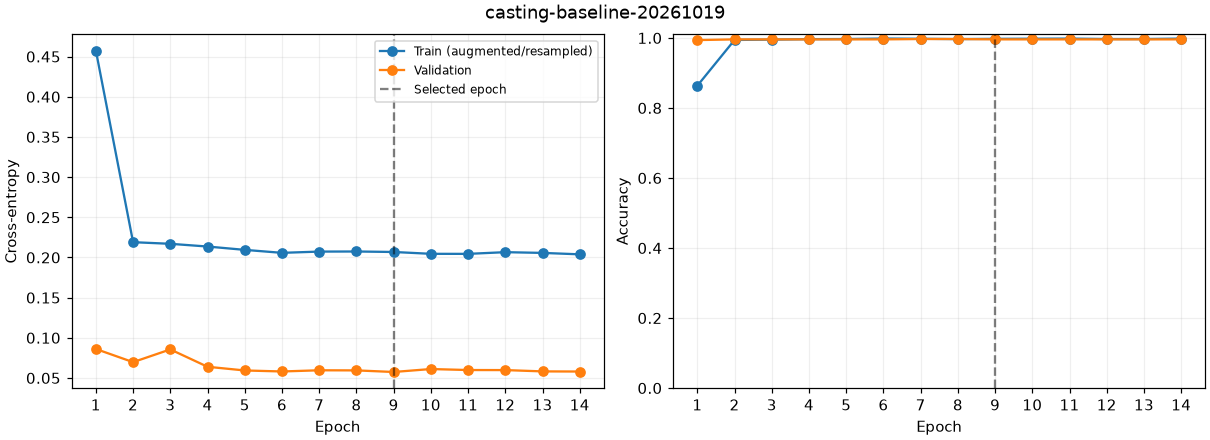

In [3]:
epochs = [row["epoch"] for row in history]
best = run["best_epoch"]
assert best == min(history, key=lambda row: row["val"]["loss"])["epoch"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for split, label in (("train", "Train (augmented/resampled)"), ("val", "Validation")):
    axes[0].plot(epochs, [row[split]["loss"] for row in history], marker="o", label=label)
    axes[1].plot(epochs, [row[split]["accuracy"] for row in history], marker="o", label=label)
for axis in axes:
    axis.axvline(best, color="black", linestyle="--", alpha=.5, label="Selected epoch")
    axis.set_xlabel("Epoch")
    axis.set_xticks(epochs)
    axis.grid(alpha=.2)
axes[0].set_ylabel("Cross-entropy")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.01)
axes[0].legend(fontsize=8)
fig.suptitle(result["run_id"])
plt.show()
print(f"Completed {run['epochs_completed']} epochs; selected epoch {best}; {run['stop_reason']}")
print("Successful optimizer steps:", sum(row["train"]["optimizer_steps"] for row in history))


## Held-out results

Predictions use the largest softmax probability (no test-tuned threshold).
The two-class ROC-AUC treats `defective` as positive. The confusion matrix has
true labels on rows and predicted labels on columns; an actual defect predicted
as `ok` is a missed defect.


Split         Images   Accuracy   Macro F1    ROC-AUC
val              986   99.5943%   0.995862   0.999950
test             715   99.7203%   0.996993   0.999890

Test metrics per class:
ok         n=262 precision=99.2424% recall=100.0000% F1=0.996198
defective  n=453 precision=100.0000% recall=99.5585% F1=0.997788
Missed defects: 2
Good images flagged defective: 0


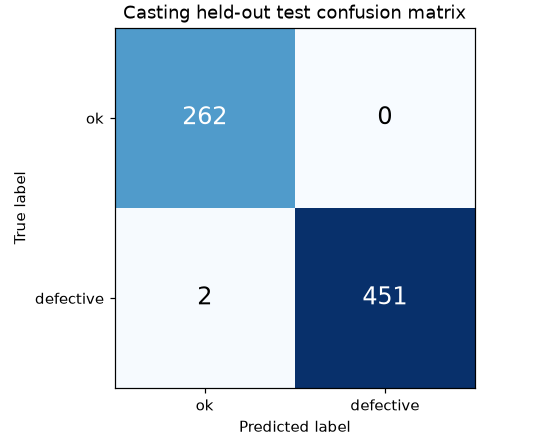

In [4]:
print(f"{'Split':12s} {'Images':>7s} {'Accuracy':>10s} {'Macro F1':>10s} {'ROC-AUC':>10s}")
for report in (validation, test):
    m = report["metrics"]
    print(f"{report['split']:12s} {m['samples']:7d} {m['accuracy']:10.4%} {m['macro_f1']:10.6f} {m['roc_auc']:10.6f}")
print("\nTest metrics per class:")
for name, metrics in test["metrics"]["per_class"].items():
    print(f"{name:10s} n={metrics['support']:3d} precision={metrics['precision']:.4%} recall={metrics['recall']:.4%} F1={metrics['f1']:.6f}")

matrix = test["metrics"]["confusion_matrix"]
counts = np.array(matrix["counts"])
fig, axis = plt.subplots(figsize=(5, 4), layout="constrained")
axis.imshow(counts, cmap="Blues", vmin=0)
axis.set_xticks(range(len(counts)), matrix["class_names"])
axis.set_yticks(range(len(counts)), matrix["class_names"])
axis.set(xlabel="Predicted label", ylabel="True label", title="Casting held-out test confusion matrix")
for row in range(len(counts)):
    for column in range(len(counts)):
        axis.text(column, row, str(counts[row, column]), ha="center", va="center",
                  color="white" if counts[row, column] > counts.max() / 2 else "black", fontsize=16)
plt.show()
print("Missed defects:", counts[1, 0])
print("Good images flagged defective:", counts[0, 1])


In [5]:
mistakes = test["metrics"]["confident_mistakes"]
print("Most confident test mistakes (up to 16):")
for mistake in mistakes:
    print(f"{mistake['true_label']} -> {mistake['predicted_label']}; "
          f"confidence={mistake['confidence']:.4f}; {mistake['image_key']}")
if not mistakes:
    print("None in this test split.")


Most confident test mistakes (up to 16):
defective -> ok; confidence=0.9102; raw/casting-v2/casting_data/casting_data/test/def_front/cast_def_0_150.jpeg
defective -> ok; confidence=0.8561; raw/casting-v2/casting_data/casting_data/test/def_front/cast_def_0_1591.jpeg


## ONNX parity and CPU latency

The ONNX graph uses opset 17 and dynamic batches. The check compares all logits
on 32 test images at batches 1 and 8, using an absolute tolerance of 0.001.
This is a numerical conversion check, separate from classification accuracy.

Latency is measured locally on CPU: 10 warmups and 200 single-image calls with
2 intra-op threads. It excludes decoding, preprocessing, session initialization,
HTTP and network overhead. It is not end-to-end service latency.


In [6]:
parity = verification["parity"]
latency = verification["latency"]
assert parity["passed"] and parity["meets_32_test_image_check"]
assert parity["split"] == "test" and parity["samples"] >= 32
print("Maximum absolute logit error:", parity["max_absolute_error"])
print("Batch sizes:", parity["batch_sizes"])
print("CPU:", verification["runtime"]["cpu_model"])
print(f"ONNX mean: {latency['mean_ms']:.2f} ms; p95: {latency['p95_ms']:.2f} ms")
recall = test["metrics"]["per_class"]["defective"]["recall"]
print("Defective recall >= 97%:", recall >= .97)
print("ONNX mean <= 50 ms:", latency["mean_ms"] <= 50)
print("ONNX p95 <= 50 ms:", latency["p95_ms"] <= 50)


Maximum absolute logit error: 2.2649765014648438e-06
Batch sizes: [1, 8]
CPU: AMD Ryzen 5 5600H with Radeon Graphics
ONNX mean: 16.96 ms; p95: 17.51 ms
Defective recall >= 97%: True
ONNX mean <= 50 ms: True
ONNX p95 <= 50 ms: True


## Reproduce and continue

Use the pinned training environment and the commands in
[`docs/RESULTS.md`](../docs/RESULTS.md). Training runs on the remote VM; saved
weights can be evaluated and exported locally. The JSON snapshot in this
notebook records hashes for the original run files so copied artifacts can be
checked. Use new output directories when reproducing; existing runs are refused.

The next baseline is NEU-DET detection. Application services, deployment, and
active learning follow once the baseline milestone is complete.
